In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
from IPython.display import Image
from tyssue.topology.base_topology import remove_face
import os


from tyssue import config, Sheet, SheetGeometry, History, EventManager
from tyssue.draw import sheet_view
from tyssue.generation import three_faces_sheet
from tyssue.draw.plt_draw import plot_forces

from tyssue.dynamics import PlanarModel

from tyssue.solvers.viscous import EulerSolver
from tyssue.draw.plt_draw import create_gif


import numpy as np
from tyssue.config.geometry import flat_sheet
from tyssue import Sheet, Monolayer, config, SheetGeometry
import pandas as pd

In [3]:
rows = [
    (-1, 3),
    (-2, 4),
    (-3, 5),
    (-3, 4),
    (-3, 3),
]

side = 1.0
vertex_coords = []
faces = []
vertex_lookup = {}

angles = np.deg2rad([90, 150, 210, 270, 330, 390])

for row, (q_start, count) in enumerate(rows):
    for q in range(q_start, q_start + count):
        cx = np.sqrt(3) * side * (q + row / 2)
        cy = 1.5 * side * row

        face = []
        for angle in angles:
            x = cx + side * np.cos(angle)
            y = cy + side * np.sin(angle)
            key = (round(x, 8), round(y, 8))

            if key not in vertex_lookup:
                vertex_lookup[key] = len(vertex_coords)
                vertex_coords.append([x, y])

            face.append(vertex_lookup[key])

        faces.append(face)

vertex_coords = np.asarray(vertex_coords, dtype=float)

# Disorder the shared vertices while keeping the mesh connected
rng = np.random.default_rng(7)
vertex_coords += rng.normal(scale=0.06, size=vertex_coords.shape)

def polygon_area(coords, face):
    points = coords[face]
    x, y = points[:, 0], points[:, 1]
    return 0.5 * abs(
        np.dot(x, np.roll(y, -1)) - np.dot(y, np.roll(x, -1))
    )

# Scale the whole sheet so its mean cell area is exactly 2
areas = np.array([polygon_area(vertex_coords, face) for face in faces])
vertex_coords *= np.sqrt(2.0 / areas.mean())

# Lists to use when constructing your Tyssue sheet
vertex_coords = vertex_coords.tolist()
preferred_areas = [2.0] * len(faces)

print("vertex_coords =", vertex_coords)
print("faces =", faces)
print("preferred_areas =", preferred_areas)

vertex_coords = [[-1.517523875300143, 0.891885449924981], [-2.2907944671066813, 0.3912709438873334], [-2.300285229334657, -0.4902217395695034], [-1.514426747594099, -0.8057239551248834], [-0.7846699677589039, -0.4707089452623284], [-0.7330428797144286, 0.4568519164723057], [0.0055417123830836384, 0.827264697087663], [-0.0015377919808140337, -0.8396275035875883], [0.6881278260859682, -0.46214730853244085], [0.6588454546106934, 0.370298034997666], [1.4207670439784263, 0.8638212242158899], [1.45095785816561, -0.8619195683577169], [2.284623349671328, -0.4479171886646479], [2.1440747233390147, 0.4097705561130088], [-2.2789325521388353, 2.1964071331945596], [-3.1156175664688996, 1.7272444341045379], [-3.086618630778419, 0.8336589269589253], [-1.4618162462258444, 1.7099075590466262], [-0.7605039650781316, 2.236943479175519], [-0.03068034706551832, 1.7464880485865926], [0.7646014621397045, 2.1938034475898713], [1.4531863692076925, 1.7563630640105223], [2.3478172651828326, 2.109115740242179], [

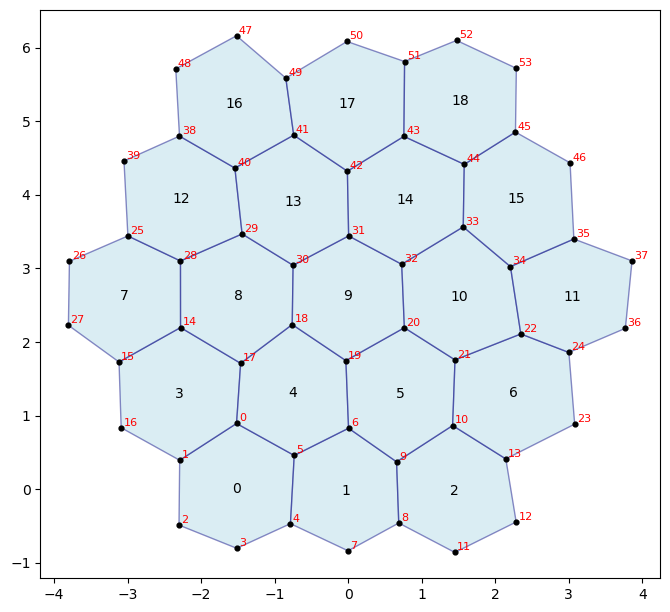

In [5]:
from tyssue.draw import sheet_view 



import numpy as np
import matplotlib.pyplot as plt

coords = np.asarray(vertex_coords)

fig, ax = plt.subplots(figsize=(8, 8))

for face_id, face in enumerate(faces):
    points = coords[face]

    # Draw the cell
    ax.fill(
        points[:, 0], points[:, 1],
        facecolor="lightblue",
        edgecolor="navy",
        alpha=0.45,
    )

    # Label the cell near its center
    ax.text(
        points[:, 0].mean(),
        points[:, 1].mean(),
        str(face_id),
        ha="center",
        va="center",
    )

# Draw and label vertices
ax.scatter(coords[:, 0], coords[:, 1], color="black", s=12)

for vertex_id, (x, y) in enumerate(coords):
    ax.text(x + 0.03, y + 0.03, str(vertex_id), color="red", fontsize=8)

ax.set_aspect("equal")
ax.autoscale()
plt.show()

In [7]:

import numpy as np
import pandas as pd

from tyssue import Sheet, PlanarGeometry
from tyssue.draw import sheet_view

# Vertex table
vert_df = pd.DataFrame(
    np.asarray(vertex_coords),
    columns=["x", "y"],
)
vert_df.index.name = "vert"
vert_df["is_active"] = 1

# One directed edge for each side of each face
edge_rows = []
for face_id, vertices in enumerate(faces):
    for i, srce in enumerate(vertices):
        trgt = vertices[(i + 1) % len(vertices)]
        edge_rows.append({
            "srce": srce,
            "trgt": trgt,
            "face": face_id,
            "is_active": 1,
            "line_tension": 0.01,
        })

edge_df = pd.DataFrame(edge_rows)
edge_df.index.name = "edge"

# One row per cell
face_df = pd.DataFrame(index=pd.Index(range(len(faces)), name="face"))
face_df["is_alive"] = 1
face_df["prefered_area"] = 2.0
face_df["area_elasticity"] = 1.0

datasets = {
    "vert": vert_df,
    "edge": edge_df,
    "face": face_df,
}

# Construct the Tyssue sheet and calculate geometry
sheet = Sheet(
    "disordered_hexagons",
    datasets,
    coords=["x", "y"],
)

geom = PlanarGeometry
sheet.reset_topo()
geom.update_all(sheet)

print("Valid mesh:", sheet.validate())

Valid mesh: True


C:\Users\Aryan\AppData\Local\Temp\ipykernel_34592\1271006820.py:54: DeprecationWarning: `alltrue` is deprecated as of NumPy 1.25.0, and will be removed in NumPy 2.0. Please use `all` instead.
  print("Valid mesh:", sheet.validate())


Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261111_033759_380525.png


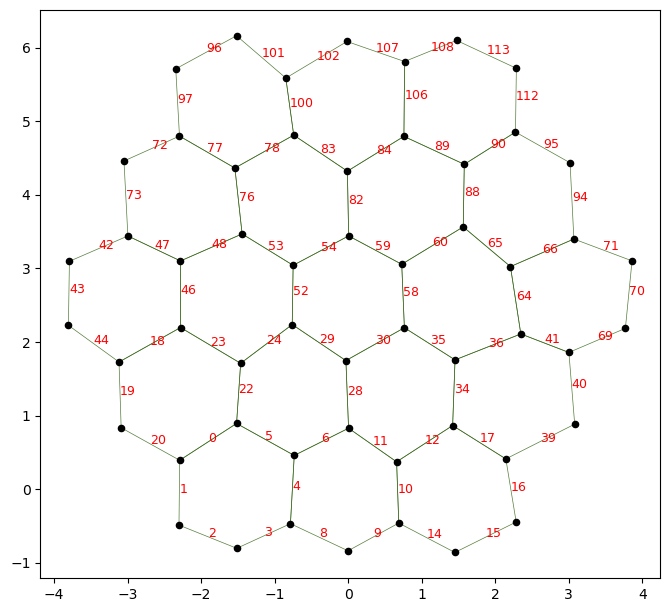

In [9]:
fig, ax = sheet_view(sheet)
ax.set_aspect("equal")
fig.set_size_inches(8, 8)

sheet.get_opposite()

for edge, data in sheet.edge_df.iterrows():
    opposite = data.opposite

    # Keep boundary edges and only one row from each shared pair
    if opposite == -1 or edge < opposite:
        x = (sheet.vert_df.loc[data.srce, "x"] +
             sheet.vert_df.loc[data.trgt, "x"]) / 2
        y = (sheet.vert_df.loc[data.srce, "y"] +
             sheet.vert_df.loc[data.trgt, "y"]) / 2
        ax.text(x, y, str(edge), color="red", fontsize=9)

In [11]:
vertices = sheet.vert_df  # bu this we can get the vertices coords and store it in vertices

display(vertices)


,x,y,is_active,z,rho,height,basal_shift
vert,,,,,,,
0,-1.517524,0.891885,1,0.0,0.0,0.0,4.0
1,-2.290794,0.391271,1,0.0,0.0,0.0,4.0
2,-2.300285,-0.490222,1,0.0,0.0,0.0,4.0
3,-1.514427,-0.805724,1,0.0,0.0,0.0,4.0
4,-0.784670,-0.470709,1,0.0,0.0,0.0,4.0
5,-0.733043,0.456852,1,0.0,0.0,0.0,4.0
6,0.005542,0.827265,1,0.0,0.0,0.0,4.0
7,-0.001538,-0.839628,1,0.0,0.0,0.0,4.0
8,0.688128,-0.462147,1,0.0,0.0,0.0,4.0


In [13]:
# print(sheet.vert_df[["x", "y"]]);
# print(sheet.face_df[["area", "num_sides"]])
# sheet.face_df

In [15]:
valid_faces = sheet.face_df.index[sheet.face_df["area"] > 1e-12] # condition for a valid face

face_id = []

for faces in valid_faces:
    face_id.append(faces)
    
# print("No of valid face :", face_id)

# face_id = valid_faces[0]

# face_id = valid_faces[1]
# For this face, get its boundary's edge IDs and source vertex IDs

for ids in face_id:
    
    boundary = sheet.get_orbits("face", "srce").loc[ids]


    print("Face:", ids) # print face id
    print("Boundary edge IDs:", list(boundary.index)) # print edge id 
    print("Boundary vertex IDs:", list(boundary.values)) # print vertex id
    
    print(sheet.edge_df.loc[boundary.index, ["srce", "trgt", "length"]]) #calculating length by Euler distance           
    print(sheet.vert_df.loc[boundary.values, ["x", "y"]])

Face: 0
Boundary edge IDs: [0, 1, 2, 3, 4, 5]
Boundary vertex IDs: [0, 1, 2, 3, 4, 5]
      srce  trgt    length
edge                      
0        0     1  0.921174
1        1     2  0.881544
2        2     3  0.846827
3        3     4  0.802982
4        4     5  0.928997
5        5     0  0.897031
             x         y
vert                    
0    -1.517524  0.891885
1    -2.290794  0.391271
2    -2.300285 -0.490222
3    -1.514427 -0.805724
4    -0.784670 -0.470709
5    -0.733043  0.456852
Face: 1
Boundary edge IDs: [6, 7, 8, 9, 10, 11]
Boundary vertex IDs: [6, 5, 4, 7, 8, 9]
      srce  trgt    length
edge                      
6        6     5  0.826264
7        5     4  0.928997
8        4     7  0.865677
9        7     8  0.786212
10       8     9  0.832960
11       9     6  0.797261
             x         y
vert                    
6     0.005542  0.827265
5    -0.733043  0.456852
4    -0.784670 -0.470709
7    -0.001538 -0.839628
8     0.688128 -0.462147
9     0.658845  0.3

In [17]:
for ids in face_id:
    
    boundary = sheet.get_orbits("face", "srce").loc[ids]

    vertex_ids = boundary.values # boundary.values gives the vertex IDs, and ["x", "y"] selects their coordinate
    coordinates = sheet.vert_df.loc[vertex_ids, ["x", "y"]] # .loc[rows, columns]
    display(coordinates)

,x,y
vert,,
0,-1.517524,0.891885
1,-2.290794,0.391271
2,-2.300285,-0.490222
3,-1.514427,-0.805724
4,-0.784670,-0.470709
5,-0.733043,0.456852


,x,y
vert,,
6,0.005542,0.827265
5,-0.733043,0.456852
4,-0.784670,-0.470709
7,-0.001538,-0.839628
8,0.688128,-0.462147
9,0.658845,0.370298


,x,y
vert,,
10,1.420767,0.863821
9,0.658845,0.370298
8,0.688128,-0.462147
11,1.450958,-0.861920
12,2.284623,-0.447917
13,2.144075,0.409771


,x,y
vert,,
14,-2.278933,2.196407
15,-3.115618,1.727244
16,-3.086619,0.833659
1,-2.290794,0.391271
0,-1.517524,0.891885
17,-1.461816,1.709908


,x,y
vert,,
18,-0.760504,2.236943
17,-1.461816,1.709908
0,-1.517524,0.891885
5,-0.733043,0.456852
6,0.005542,0.827265
19,-0.030680,1.746488


,x,y
vert,,
20,0.764601,2.193803
19,-0.030680,1.746488
6,0.005542,0.827265
9,0.658845,0.370298
10,1.420767,0.863821
21,1.453186,1.756363


... (9 outputs left out)

,x,y
vert,,
45,2.275114,4.854128
44,1.578893,4.415234
33,1.564837,3.564926
34,2.206804,3.024856
35,3.069185,3.399978
46,3.017310,4.436212


,x,y
vert,,
47,-1.517872,6.163930
48,-2.344246,5.713396
38,-2.293585,4.799615
40,-1.540090,4.364936
41,-0.740258,4.812642
49,-0.847545,5.588172


,x,y
vert,,
50,-0.016007,6.085951
49,-0.847545,5.588172
41,-0.740258,4.812642
42,-0.010371,4.322333
43,0.758189,4.795671
51,0.767419,5.813180


,x,y
vert,,
52,1.473864,6.100460
51,0.767419,5.813180
43,0.758189,4.795671
44,1.578893,4.415234
45,2.275114,4.854128
53,2.287181,5.721089


In [19]:
from tyssue.dynamics import effectors, model_factory

area_model = model_factory([
    effectors.FaceAreaElasticity,
    effectors.LineTension
    # effectors.PerimeterElasticity
])

sheet.update_specs(area_model.specs, reset=True)

# Area energy parameters
### Pandas warns because chained indexing (["column"].iloc[]) may modify a temporary view rather than the original DataFrame. ###
# sheet.face_df["area_elasticity"].iloc[0] = 1.0
# sheet.face_df["area_elasticity"].iloc[0] = 1.0

# sheet.face_df["prefered_area"].iloc[0] = 8.0
# sheet.face_df["prefered_area"].iloc[1] = 8.0

# Area elasticity for both faces
sheet.face_df["area_elasticity"] = 1.0

# Preferred area for both faces
sheet.face_df.loc[0, "prefered_area"] = 8.0
sheet.face_df.loc[1, "prefered_area"] = 6.0
sheet.face_df.loc[2, "prefered_area"] = 8.0
sheet.face_df.loc[3, "prefered_area"] = 14.0
sheet.face_df.loc[4, "prefered_area"] = 10.0
sheet.face_df.loc[5, "prefered_area"] = 9.0
sheet.face_df.loc[6, "prefered_area"] = 8.0
sheet.face_df.loc[7, "prefered_area"] = 8.0
sheet.face_df.loc[8, "prefered_area"] = 6.0
sheet.face_df.loc[9, "prefered_area"] = 8.0
sheet.face_df.loc[10, "prefered_area"] = 14.0
sheet.face_df.loc[11, "prefered_area"] = 10.0
sheet.face_df.loc[12, "prefered_area"] = 9.0
sheet.face_df.loc[13, "prefered_area"] = 8.0
sheet.face_df.loc[14, "prefered_area"] = 8.0
sheet.face_df.loc[15, "prefered_area"] = 6.0
sheet.face_df.loc[16, "prefered_area"] = 8.0
sheet.face_df.loc[17, "prefered_area"] = 14.0
sheet.face_df.loc[18, "prefered_area"] = 10.0
sheet.face_df.loc[19, "prefered_area"] = 9.0
# target_area = sheet.face_df["prefered_area"].iloc[0]

# line tension affector value
sheet.edge_df["line_tension"] = 2.0

# Perimeter energy parameters
# sheet.face_df["perimeter_elasticity"] = 1.0
# sheet.face_df["prefered_perimeter"] = 6 * np.sqrt(4 * target_area/ (3 * np.sqrt(3)))
# sheet.face_df["prefered_perimeter"] = 6.0 # this gives a regular hexagon shape 


geom.update_all(sheet)
# print(target_area)

Reseting column is_alive of the face dataset with new specs
Reseting column area of the face dataset with new specs
Reseting column area_elasticity of the face dataset with new specs
Reseting column prefered_area of the face dataset with new specs
Reseting column sub_area of the edge dataset with new specs
Reseting column is_active of the edge dataset with new specs
Reseting column line_tension of the edge dataset with new specs


In [21]:
import numpy as np

grad_E = area_model.compute_gradient(sheet)

grad_E["magnitude"] = np.sqrt(grad_E["gx"]**2 + grad_E["gy"]**2)

print(grad_E[["gx", "gy", "magnitude"]])

area_model.specs

            gx        gy  magnitude
srce                               
0    -2.784631  3.234344   4.267921
1     3.007091  6.380276   7.053405
2     2.652221  1.701736   3.151219
3    -0.039343  3.757071   3.757277
4    -1.188756  2.717392   2.966034
5    -1.046283  2.410235   2.627535
6    -0.308684  2.386671   2.406551
7     0.009577  2.167681   2.167702
8     1.245179  2.707966   2.980528
9     1.061238  1.105341   1.532320
10   -0.871263  0.505787   1.007432
11   -0.052731  3.896156   3.896512
12   -2.770170  1.544079   3.171438
13   -3.363425  1.759885   3.796027
14   -1.428544 -5.647595   5.825467
15    7.201039 -0.760636   7.241100
16    7.077880  4.375835   8.321317
17   -2.147110 -4.749240   5.212041
18    1.340770 -1.823691   2.263518
19   -0.902893 -1.193397   1.496467
20    3.937770  1.485322   4.208588
21   -0.597878  4.608390   4.647012
22   -2.242481  2.636054   3.460852
23   -3.289941  1.978710   3.839141
24   -3.055135  3.492995   4.640567
25    3.915707 -1.612035   4

{'cell': {},
 'face': {'is_alive': 1,
  'area': 1.0,
  'area_elasticity': 1.0,
  'prefered_area': 1.0},
 'edge': {'sub_area': 0.16666666666666666,
  'is_active': 1,
  'line_tension': 1.0},
 'vert': {},
 'settings': {'nrj_norm_factor': 1.0}}

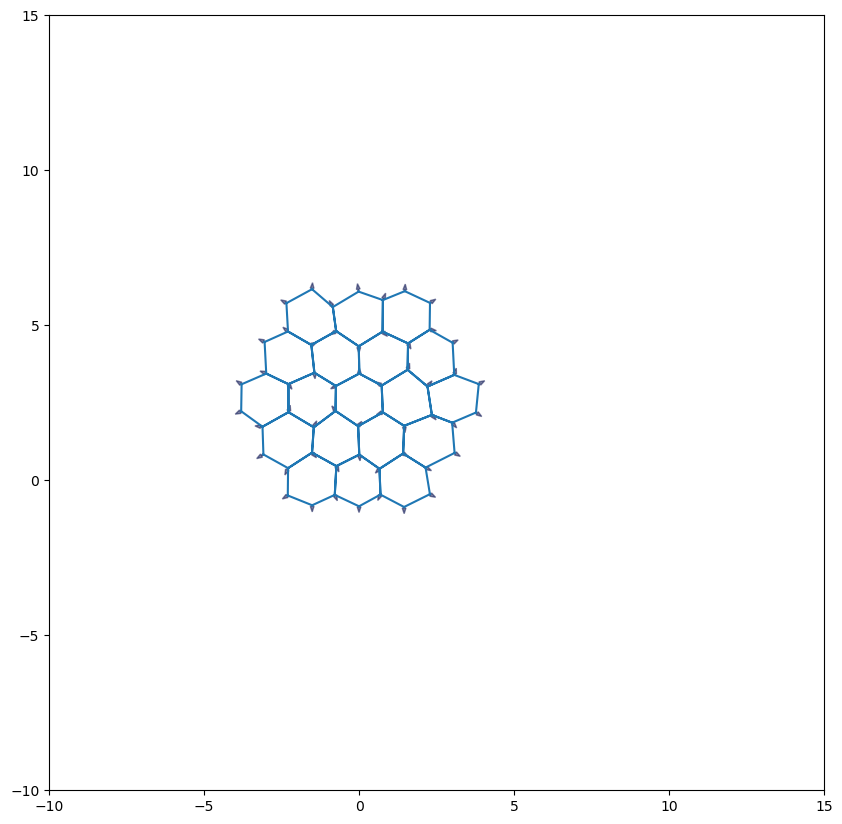

In [23]:
from tyssue.draw.plt_draw import plot_forces


fig, ax = plot_forces(sheet, geom, area_model, ['x', 'y'], scaling=0.009)
ax.set_xlim(-10, 15)
ax.set_ylim(-10, 15)

fig.set_size_inches(10, 12)

Successfull gradient descent?  True
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261110_030529_214098.png


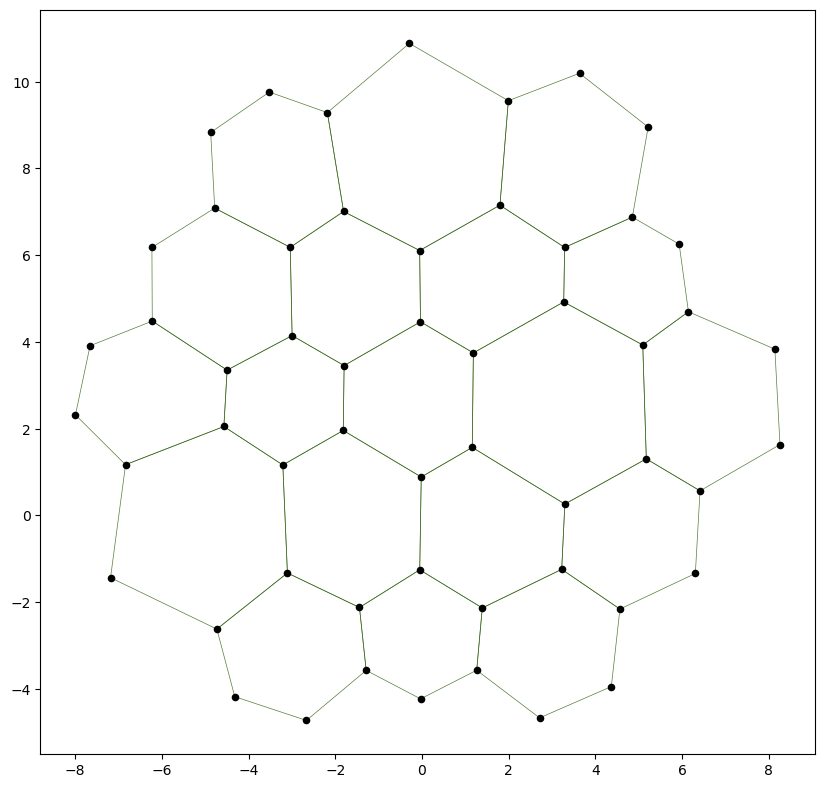

In [47]:
from tyssue.solvers import QSSolver

solver = QSSolver()
res = solver.find_energy_min(sheet, geom, area_model)

print("Successfull gradient descent? ", res['success'])
fig, ax = sheet_view(sheet)

fig.set_size_inches(10, 10)
ax.set_aspect('equal')

In [219]:
# Assign viscosity to every vertex
sheet.vert_df["viscosity"] = 10.0


# solver = EulerSolver(sheet, geom, area_model, auto_reconnect=False)

In [25]:
import numpy as np
import time
from tyssue.solvers.viscous import EulerSolver
from tyssue.topology.sheet_topology import type1_transition
# from pkg_resources import Requirement

# import winsound
# from win10toast import ToastNotifier

# sheet.vert_df["viscosity"] = 10.0
# solver = EulerSolver(sheet, geom, area_model)

# import warnings

# warnings.filterwarnings("ignore", category=FutureWarning)

import warnings

warnings.filterwarnings("ignore", category=FutureWarning)

dt = 0.001
chunk_steps = 20
max_chunks = 1000
tolerance = 1e-4



# edge_id = 54
# type1_transition(sheet, edge_id, multiplier=6)


sheet.vert_df["viscosity"] = 10.0



# -------- PLOT SETTINGS --------

# X-axis range (simulation time)
x_min, x_max = 0, 100
# Y-axis range for gradient X
gx_min, gx_max = -10, 10
# Y-axis range for gradient Y
gy_min, gy_max = -10, 10
# Tick intervals (unit length)
x_tick, gx_tick, gy_tick = 10, 2, 2










geom.update_all(sheet)

start = time.perf_counter()


times = []

vertex_ids = sheet.vert_df.index.tolist()

gx_history = {vid: [] for vid in vertex_ids}
gy_history = {vid: [] for vid in vertex_ids}







threshold = 0.05
T1_MULTIPLIER = 1.5

highlight_cutoff = max(2.0, T1_MULTIPLIER + 0.2) * threshold    # gets the value of threshold and 

sheet.settings["threshold_length"] = threshold
history = History(sheet)

def reconnect_with_multiplier(sheet, manager, multiplier):
    # Refresh edge lengths, then find unique interior edges below threshold.
    geom.update_all(sheet)
    sheet.get_opposite()

    edges = sheet.edge_df
    candidates = edges[
        (edges["opposite"] > -1)
        & (edges.index < edges["opposite"])
        & (edges["length"] < sheet.settings["threshold_length"])
    ]

    if not candidates.empty:
        edge_id = candidates["length"].idxmin()
        type1_transition(sheet, edge_id, multiplier=multiplier)
        geom.update_all(sheet)
        print(f"T1 on edge {edge_id}; multiplier={multiplier}")

    # Check again at the next solver step.
    manager.append(reconnect_with_multiplier, multiplier=multiplier)

manager = EventManager("face")
manager.append(reconnect_with_multiplier, multiplier=T1_MULTIPLIER)
manager.update()

# Solver setup
solver = EulerSolver(sheet, geom, area_model, auto_reconnect=False, manager=manager,)


# Define the drawing function before running the simulation (draw the T1 transition edge)
def draw_t1_frame(frame_sheet):
    geom.update_all(frame_sheet)
    frame_sheet.get_opposite()

    fig, ax = sheet_view(frame_sheet, mode="2D", edge={"color": "blue"})

    edges = frame_sheet.edge_df
    near_t1 = edges[
        (edges["opposite"] > -1)
        & (edges.index < edges["opposite"])
        & (edges["length"] < highlight_cutoff)
    ]

    for _, edge in near_t1.iterrows():
        points = frame_sheet.vert_df.loc[
            [edge["srce"], edge["trgt"]], ["x", "y"]
        ].to_numpy()
        ax.plot(
            points[:, 0], points[:, 1],
            color="crimson", linewidth=4, zorder=10
        )

    return fig, ax


# try: 
for chunk in range(max_chunks):
    # Advance the model by a chunk of time
    tf = (chunk + 1) * chunk_steps * dt
    solver.solve(tf=tf, dt=dt)

    grad = area_model.compute_gradient(sheet)
    grad_active = grad.loc[sheet.active_verts, ["gx", "gy"]].to_numpy()

    if not np.isfinite(grad_active).all():
        print("Simulation became numerically unstable.")
        break

    max_gradient = np.linalg.norm(grad_active, axis=1).max()


    times.append(tf)

    for vid in vertex_ids:
        if vid in grad.index:
            gx_history[vid].append(grad.loc[vid, "gx"])
            gy_history[vid].append(grad.loc[vid, "gy"])

        else:
            gx_history[vid].append(np.nan)
            gy_history[vid].append(np.nan)
    
   
    if chunk % 10 == 0:
        print(f"Chunk {chunk}: " f"max gradient = {max_gradient:.3e}")
              # f"ΔE = {delta_energy:.6f}, "
              # f"junction length = {junction_length:.6f}")

    # check convergence 
    if max_gradient < tolerance:
        print(f"Converged after {chunk + 1} chunks.")
        break

print(f"Elapsed time: {time.perf_counter() - start:.2f} seconds")


Chunk 0: max gradient = 8.900e+00
Chunk 10: max gradient = 9.125e+00
Chunk 20: max gradient = 9.318e+00
Chunk 30: max gradient = 9.521e+00
Chunk 40: max gradient = 9.509e+00
Chunk 50: max gradient = 9.292e+00
Chunk 60: max gradient = 8.920e+00
T1 on edge 88; multiplier=1.5
Chunk 70: max gradient = 8.464e+00
Chunk 80: max gradient = 7.980e+00
Chunk 90: max gradient = 7.533e+00
Chunk 100: max gradient = 7.108e+00
Chunk 110: max gradient = 6.712e+00
Chunk 120: max gradient = 6.346e+00
Chunk 130: max gradient = 6.024e+00
Chunk 140: max gradient = 5.740e+00
Chunk 150: max gradient = 5.479e+00
Chunk 160: max gradient = 5.239e+00
Chunk 170: max gradient = 5.016e+00
Chunk 180: max gradient = 4.803e+00
Chunk 190: max gradient = 4.596e+00
Chunk 200: max gradient = 4.398e+00
Chunk 210: max gradient = 4.206e+00
Chunk 220: max gradient = 4.021e+00
Chunk 230: max gradient = 3.955e+00
Chunk 240: max gradient = 3.674e+00
Chunk 250: max gradient = 3.511e+00
Chunk 260: max gradient = 3.355e+00
Chunk 270

In [123]:
print(gx_history)

{52: [-0.37625844540450204, -0.4036494431645863, -0.4307275404787577, -0.4574933705681564, -0.4839473355522831, -0.5100896096391571, -0.5359201426931747, -0.5614386642542433, -0.5866446880713561, -0.6115375172050652, -0.6361162497443231, -0.6603797851757947, -0.6843268314355249, -0.7079559126663842, -0.7312653776970766, -0.7542534092520317, -0.7769180338947648, -0.7992571327003567, -0.8212684526464235, -0.8429496187054709, -0.864298146614843, -0.8853114562944728, -0.9059868858761919, -0.9263217063025749, -0.9463131364473315, -0.9659583587038092, -0.985254534982662, -1.0041988230552101, -1.0227883931741597, -1.0410204448995306, -1.0588922240538303, -1.0764010397279238, -1.0935442812560803, -1.1103194350774848, -1.1267241014000249, -1.1427560105819414, -1.1584130391471703, -1.1736932253513994, -1.1885947842174385, -1.2031161219613247, -1.2172558497334875, -1.2310127966035092, -1.244386021721506, -1.2573748255943595, -1.2699787604207984, -1.282197639435723, -1.2940315452209576, -1.3054808

In [155]:
vertex_ids = sheet.vert_df.index.tolist()
print("Vertices being tracked:", len(vertex_ids))

Vertices being tracked: 54


C:\Users\Aryan\AppData\Local\Temp\ipykernel_21780\4291723458.py:53: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


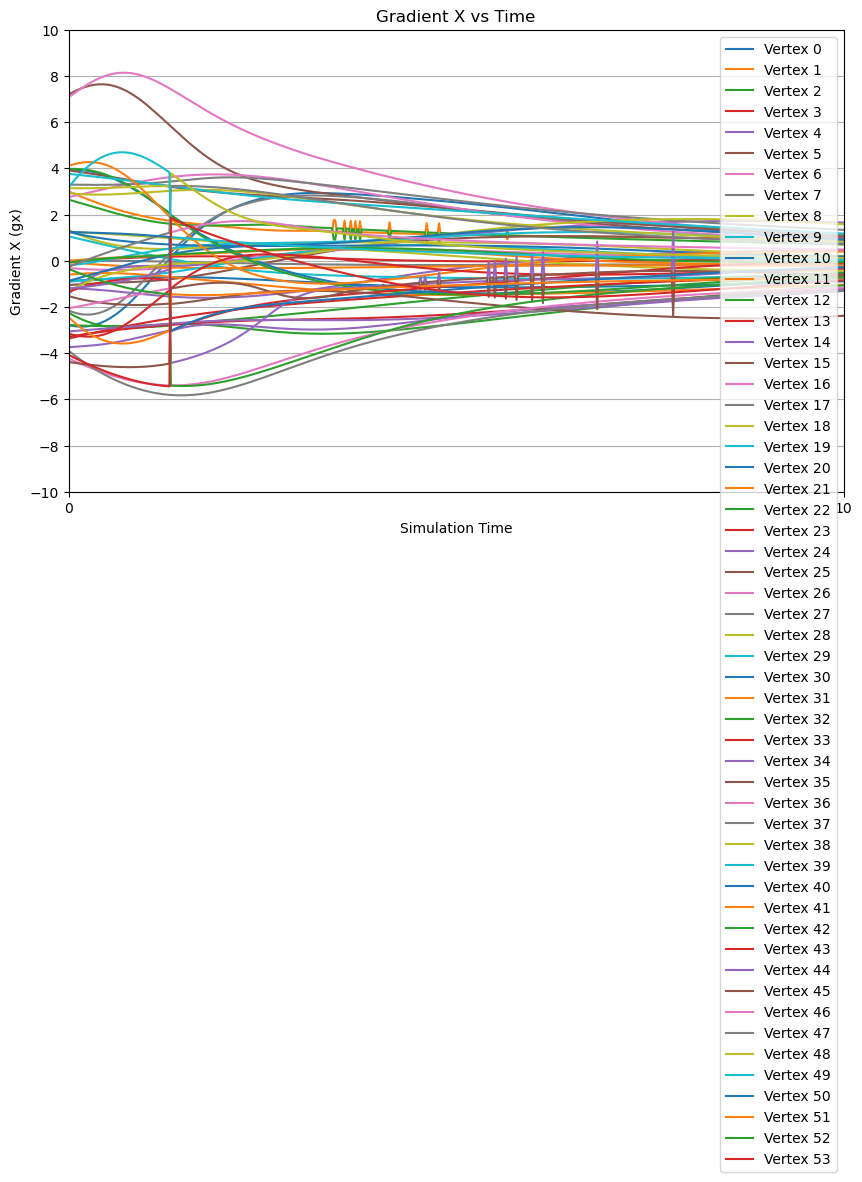

C:\Users\Aryan\AppData\Local\Temp\ipykernel_21780\4291723458.py:90: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


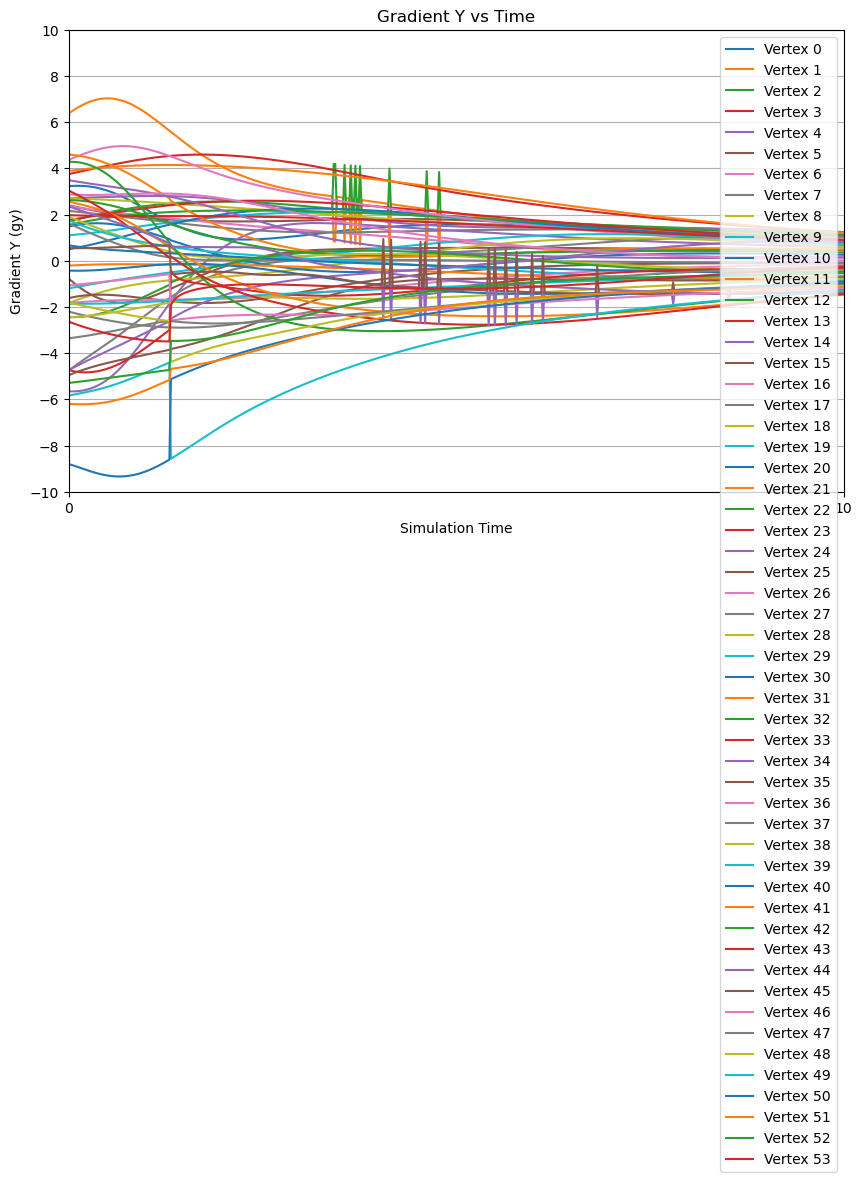

In [157]:
# plotting the dynamics of force gradient in the vertex  

# import matplotlib.pyplot as plt
# from matplotlib.ticker import MultipleLocator
# import time

# import os


# # Create one directory for both plots
# save_dir = r"C:\Users\Aryan\Tyssue_outputs"
# # os.makedirs(save_dir, exist_ok=True)


# # -------- PLOT SETTINGS --------

# # X-axis range (simulation time)
# x_min, x_max = 0, 10
# # Y-axis range for gradient X
# gx_min, gx_max = -10, 10
# # Y-axis range for gradient Y
# gy_min, gy_max = -10, 10
# # Tick intervals (unit length)
# x_tick, gx_tick, gy_tick = 10, 2, 2


# plt.figure(figsize=(10, 6))

# for vid in vertex_ids:
#     plt.plot(
#         times,
#         gx_history[vid],
#         label=f"Vertex {vid}"
#     )

# plt.xlabel("Simulation Time")
# plt.ylabel("Gradient X (gx)")
# plt.title("Gradient X vs Time")

# plt.xlim(x_min, x_max)
# plt.ylim(gx_min, gx_max)

# plt.gca().xaxis.set_major_locator(
#     MultipleLocator(x_tick)
# )

# plt.gca().yaxis.set_major_locator(
#     MultipleLocator(gx_tick)
# )

# plt.legend()
# plt.grid(True)
# plt.tight_layout()

# plt.savefig(os.path.join(save_dir, "gradient_x.png"),
#             dpi=300, bbox_inches="tight")
# plt.show()






# plt.figure(figsize=(10, 6))

# for vid in vertex_ids:
#     plt.plot(
#         times,
#         gy_history[vid],
#         label=f"Vertex {vid}"
#     )

# plt.xlabel("Simulation Time")
# plt.ylabel("Gradient Y (gy)")
# plt.title("Gradient Y vs Time")

# plt.xlim(x_min, x_max)
# plt.ylim(gy_min, gy_max)

# plt.gca().xaxis.set_major_locator(
#     MultipleLocator(x_tick)
# )

# plt.gca().yaxis.set_major_locator(
#     MultipleLocator(gy_tick)
# )

# plt.legend()
# plt.grid(True)
# plt.tight_layout()

# plt.savefig(os.path.join(save_dir, "gradient_y.png"),
#             dpi=300, bbox_inches="tight")
# plt.show()


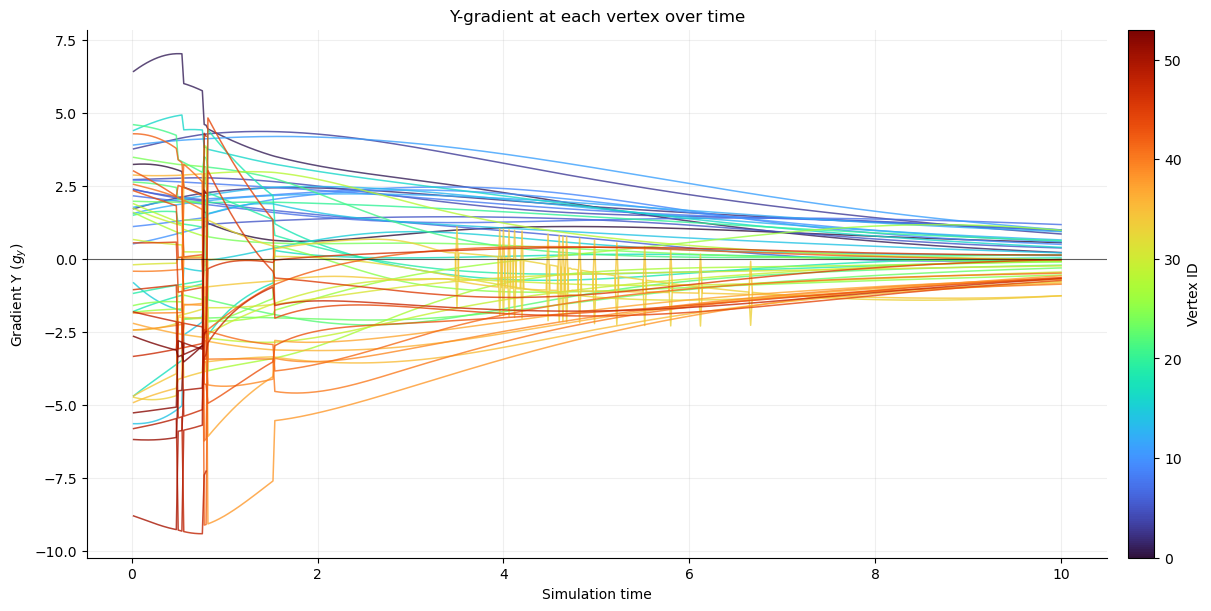

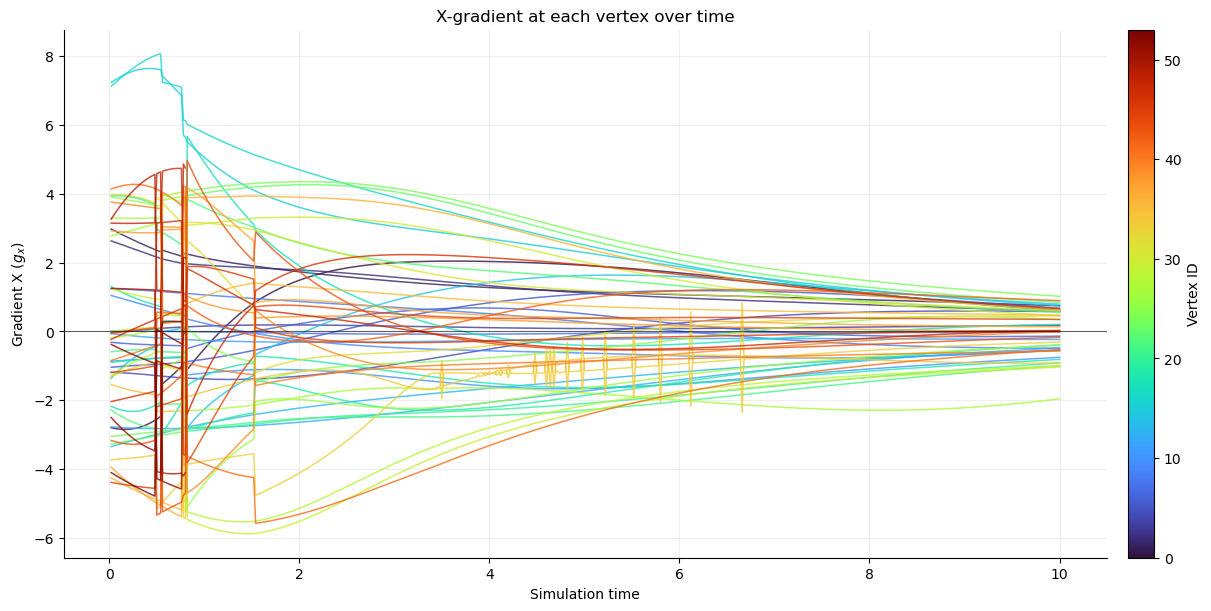

In [223]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

vertex_ids = sorted(gy_history)
norm = Normalize(vmin=min(vertex_ids), vmax=max(vertex_ids))
cmap = plt.get_cmap("turbo")

fig, ax = plt.subplots(figsize=(12, 6), constrained_layout=True)

for vid in vertex_ids:
    values = np.asarray(gy_history[vid], dtype=float)
    if len(values) == len(times):
        ax.plot(
            times, values,
            color=cmap(norm(vid)),
            linewidth=1.1,
            alpha=0.8,
        )
    
ax.axhline(0, color="black", linewidth=0.8, alpha=0.6)
ax.set(
    title="Y-gradient at each vertex over time",
    xlabel="Simulation time",
    ylabel="Gradient Y ($g_y$)",
)
ax.grid(True, alpha=0.2)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

colorbar = fig.colorbar(
    ScalarMappable(norm=norm, cmap=cmap),
    ax=ax,
    pad=0.02,
)
colorbar.set_label("Vertex ID")

plt.savefig(os.path.join(save_dir, "gradient_y.png"),
            dpi=300, bbox_inches="tight")


plt.show()



vertex_ids = sorted(gx_history)
norm = Normalize(vmin=min(vertex_ids), vmax=max(vertex_ids))
cmap = plt.get_cmap("turbo")

fig, ax = plt.subplots(figsize=(12, 6), constrained_layout=True)

for vid in vertex_ids:
    values = np.asarray(gx_history[vid], dtype=float)
    if len(values) == len(times):
        ax.plot(
            times, values,
            color=cmap(norm(vid)),
            linewidth=1.1,
            alpha=0.8,
        )
    
ax.axhline(0, color="black", linewidth=0.8, alpha=0.6)
ax.set(
    title="X-gradient at each vertex over time",
    xlabel="Simulation time",
    ylabel="Gradient X ($g_x$)",
)
ax.grid(True, alpha=0.2)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

colorbar = fig.colorbar(
    ScalarMappable(norm=norm, cmap=cmap),
    ax=ax,
    pad=0.02,
)
colorbar.set_label("Vertex ID")

plt.savefig(os.path.join(save_dir, "gradient_x.png"),
            dpi=300, bbox_inches="tight")



plt.show()



In [43]:
# plot gradient energy of individual veretxes 
# Create one directory for both plots
save_dir = r"C:\Users\Aryan\Tyssue_outputs"
# os.makedirs(save_dir, exist_ok=True)

import os
import matplotlib.pyplot as plt

def plot_vertex_gradients(vertex_ids, component="gy"):
    histories = gx_history if component == "gx" else gy_history

    fig, ax = plt.subplots(figsize=(9, 5))

    for vid in vertex_ids:
        if vid not in histories:
            print(f"Vertex {vid} is not in the recorded history.")
            continue

        ax.plot(times, histories[vid], label=f"Vertex {vid}")

    ax.axhline(0, color="black", linewidth=0.8, alpha=0.5)
    ax.set_xlabel("Simulation time")
    ax.set_ylabel(f"Gradient {component[1].upper()} ({component})")
    ax.set_title(f"{component} dynamics for selected vertices")
    ax.grid(True, alpha=0.25)
    ax.legend()
    fig.tight_layout()

    plt.savefig(os.path.join(save_dir, "gradient_y_individual.png"),
            dpi=300, bbox_inches="tight")

    plt.show()

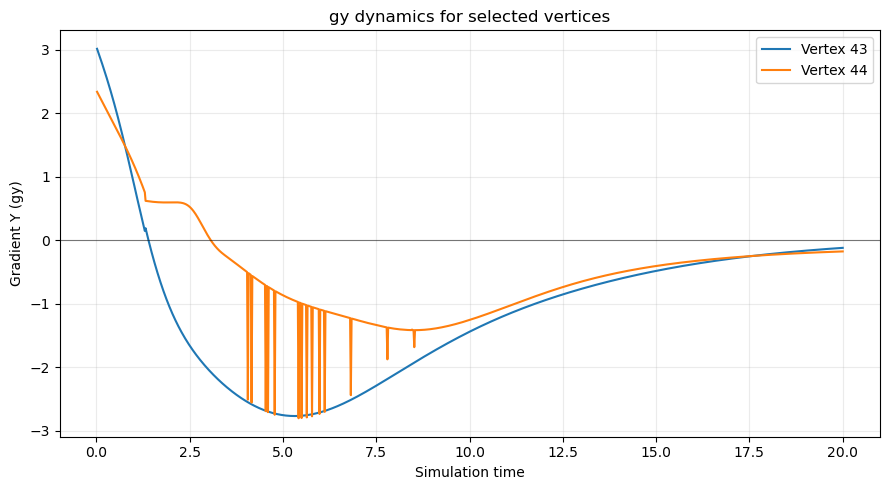

In [45]:
plot_vertex_gradients([43, 44], component="gy")

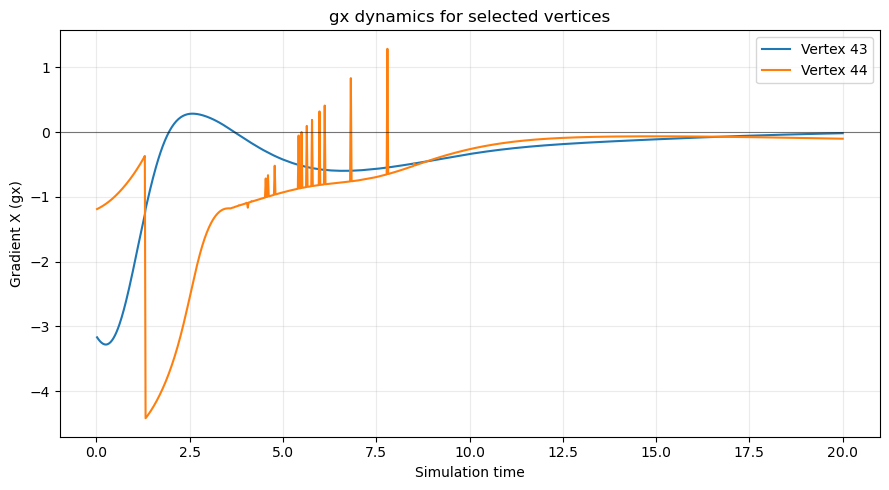

In [47]:
# plot_vertex_gradients([43, 44], component="gy")


plot_vertex_gradients([43, 44], component="gx")

In [27]:
create_gif(solver.history,"t1_highlighted.gif", draw_func=draw_t1_frame, num_frames=200)

Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261111_044251_536640.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261111_044251_818879.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261111_044252_103148.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261111_044252_381316.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261111_044252_656583.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261111_044252_990629.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261111_044253_287271.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261111_044253_599276.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261111_044253_923676.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261111_044254_274322.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261111_044254_564723.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261111_044254_864605.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261111_044255_128938.png
Plot saved: C:\Users\Arya

C:\Users\Aryan\.conda\envs\tyssue_env\lib\site-packages\tyssue\core\sheet.py:442: UserWarning: Duplicated (`srce`, `trgt`) values in edge_df, maybe sanitize your input
  warnings.warn(


Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261111_044303_960610.png


C:\Users\Aryan\.conda\envs\tyssue_env\lib\site-packages\tyssue\core\sheet.py:442: UserWarning: Duplicated (`srce`, `trgt`) values in edge_df, maybe sanitize your input
  warnings.warn(


Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261111_044304_292937.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261111_044304_579277.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261111_044304_912365.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261111_044305_213798.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261111_044305_468107.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261111_044305_762302.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261111_044306_095689.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261111_044306_467403.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261111_044306_799537.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261111_044307_123464.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261111_044307_402743.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261111_044307_671866.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261111_044307_981294.png
Plot saved: C:\Users\Arya

C:\Users\Aryan\.conda\envs\tyssue_env\lib\site-packages\tyssue\core\sheet.py:442: UserWarning: Duplicated (`srce`, `trgt`) values in edge_df, maybe sanitize your input
  warnings.warn(


... (8 outputs left out)

Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261111_044341_982857.png


C:\Users\Aryan\.conda\envs\tyssue_env\lib\site-packages\tyssue\core\sheet.py:442: UserWarning: Duplicated (`srce`, `trgt`) values in edge_df, maybe sanitize your input
  warnings.warn(


Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261111_044342_315968.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261111_044342_632509.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261111_044342_964572.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261111_044343_299175.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261111_044343_600630.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261111_044343_886168.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261111_044344_206594.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261111_044344_565198.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261111_044344_879611.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261111_044345_164592.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261111_044345_512354.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261111_044345_797118.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261111_044346_097735.png
Plot saved: C:\Users\Arya

'C:\\Users\\Aryan\\tyssue Simulations\\t1_highlighted.gif'

In [264]:
create_gif(solver.history, "sheet3.gif", num_frames=200)

Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261110_053953_964959.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261110_053954_228583.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261110_053954_474678.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261110_053954_744177.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261110_053955_026774.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261110_053955_311354.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261110_053955_595230.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261110_053955_873040.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261110_053956_136625.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261110_053956_367119.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261110_053956_632471.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261110_053956_936580.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261110_053957_174560.png
Plot saved: C:\Users\Arya

'C:\\Users\\Aryan\\tyssue Simulations\\sheet3.gif'

In [ ]:
geom.update_all(sheet)
sheet.reset_topo()

print("Face side counts:")
print(sheet.face_df["num_sides"].value_counts().sort_index())

print("\nFace areas:")
print(sheet.face_df["area"].describe())

print("\nVertex coordinate bounds:")
print(sheet.vert_df[["x", "y"]].agg(["min", "max"]))

print("\nShortest edge:", sheet.edge_df["length"].min())